# 2026-06-17 Candidate-receptor similarity heatmaps (3 strain pairs)

Pairwise protein-similarity heatmaps between the candidate phage-receptor sets of three *Pseudomonas* isolates, from the genome annotations in [`../data/0616_bacteria_genome/`](../data/0616_bacteria_genome/):

| Strain | Locus prefix | File |
|---|---|---|
| 9-6-2 | `PICBEH_` | `9-6-2_potential_receptors.fasta` |
| 9-2-1 | `OHPLIO_` | `9-2-1_potential_receptors.fasta` |
| 10-10-2 | `BPBBIK_` | `10-10-2_potential_receptors.fasta` |

**Method.** All-vs-all **MMseqs2** `easy-search`; each heatmap cell = best-hit **% identity** (`fident`) for that receptor pair, kept only if the alignment passes a coverage floor (`qcov` & `tcov` >= `COV_FLOOR`); non-homologous pairs = 0. Three pairs: 9-6-2x9-2-1, 9-6-2x10-10-2, 9-2-1x10-10-2.

**Setup (one-time):** `brew install mmseqs2`  (fallback `CONDA_SUBDIR=osx-64 conda install -c bioconda -c conda-forge mmseqs2`).

Outputs -> `output/0617_receptor_similarity/` (matrices CSV + heatmap PNGs).

In [1]:
import os, re, subprocess, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Paths (cwd = code/ when run) -------------------------------------------
DATA_DIR = Path("../data/0616_bacteria_genome")
OUT_DIR  = Path("output/0617_receptor_similarity")
OUT_DIR.mkdir(parents=True, exist_ok=True)

STRAINS = {
    "9-6-2":   DATA_DIR / "9-6-2_potential_receptors.fasta",
    "9-2-1":   DATA_DIR / "9-2-1_potential_receptors.fasta",
    "10-10-2": DATA_DIR / "10-10-2_potential_receptors.fasta",
}
MMSEQS = shutil.which("mmseqs") or "/opt/homebrew/bin/mmseqs"

# ---- Tunable parameters ------------------------------------------------------
COV_FLOOR   = 0.80   # min query & target coverage for a hit to count as homologous
SENSITIVITY = 7.5    # mmseqs -s (max sensitivity so weak hits are captured)
EVALUE      = 1000   # lenient -e so the full matrix incl. faint hits is reported
print("mmseqs:", MMSEQS)

mmseqs: /opt/homebrew/bin/mmseqs


## 1 - Parse FASTA + build combined sequence set

In [2]:
# ---- 10-line FASTA parser (no biopython needed) -----------------------------
def parse_fasta(path):
    """Return {locus_tag: sequence} for a FASTA file (header = first token)."""
    seqs, header, buf = {}, None, []
    with open(path) as fh:
        for line in fh:
            line = line.rstrip("\n")
            if line.startswith(">"):
                if header is not None: seqs[header] = "".join(buf)
                header, buf = line[1:].split()[0], []
            else:
                buf.append(line)
        if header is not None: seqs[header] = "".join(buf)
    return seqs

def locus_num(sid):
    m = re.search(r"_(\d+)$", sid)
    return int(m.group(1)) if m else -1

# Build one combined FASTA of all sequences + a seq_id -> strain map.
combined_fasta = OUT_DIR / "combined_receptors.fasta"
id2strain, counts = {}, {}
with open(combined_fasta, "w") as out:
    for strain, path in STRAINS.items():
        seqs = parse_fasta(path)
        counts[strain] = len(seqs)
        for sid, seq in seqs.items():
            id2strain[sid] = strain
            out.write(f">{sid}\n{seq}\n")
print("sequences per strain:", counts, "| total:", len(id2strain))

sequences per strain: {'9-6-2': 182, '9-2-1': 182, '10-10-2': 178} | total: 542


## 2 - All-vs-all MMseqs2 search

In [3]:
# All-vs-all search. easy-search reports hits above threshold; any pair with no
# reported hit is genuinely non-homologous -> filled with 0 in the matrices.
search_tsv = OUT_DIR / "allvall_search.tsv"
tmp_dir    = OUT_DIR / "mmseqs_tmp_search"
cols = ["query","target","fident","alnlen","qcov","tcov","bits","evalue"]
cmd = [MMSEQS, "easy-search", str(combined_fasta), str(combined_fasta),
       str(search_tsv), str(tmp_dir),
       "--format-output", ",".join(cols),
       "-s", str(SENSITIVITY), "-e", str(EVALUE),
       "--max-seqs", "1000", "-v", "1"]
print(" ".join(cmd))
subprocess.run(cmd, check=True)
hits = pd.read_csv(search_tsv, sep="\t", names=cols)
print(hits.shape[0], "hit rows")
hits.head()

/opt/homebrew/bin/mmseqs easy-search output/0617_receptor_similarity/combined_receptors.fasta output/0617_receptor_similarity/combined_receptors.fasta output/0617_receptor_similarity/allvall_search.tsv output/0617_receptor_similarity/mmseqs_tmp_search --format-output query,target,fident,alnlen,qcov,tcov,bits,evalue -s 7.5 -e 1000 --max-seqs 1000 -v 1


30976 hit rows


,query,target,fident,alnlen,qcov,tcov,bits,evalue
0,PICBEH_00005,PICBEH_00005,1.000,124,1.000,1.000,269,1.864000e-85
1,PICBEH_00005,OHPLIO_00005,1.000,124,1.000,1.000,269,1.864000e-85
2,PICBEH_00005,BPBBIK_00005,0.918,135,1.000,1.000,260,1.416000e-82
3,PICBEH_00005,BPBBIK_00346,0.545,11,0.089,0.014,17,1.565000e+02
4,PICBEH_00005,PICBEH_02082,0.320,25,0.202,0.024,15,6.673000e+02


## 3 - Build the three pairwise % identity matrices

In [4]:
def pident_matrix(hits, rows_strain, cols_strain, cov_floor=COV_FLOOR):
    """Rectangular % identity matrix: rows = rows_strain receptors, cols = cols_strain.
    Cell = best-hit % identity among hits passing the coverage floor, else 0."""
    row_ids = sorted([i for i,s in id2strain.items() if s==rows_strain], key=locus_num)
    col_ids = sorted([i for i,s in id2strain.items() if s==cols_strain], key=locus_num)
    sub = hits[(hits["query"].map(id2strain)==rows_strain) &
               (hits["target"].map(id2strain)==cols_strain) &
               (hits["qcov"]>=cov_floor) & (hits["tcov"]>=cov_floor)]
    best = sub.groupby(["query","target"])["fident"].max().mul(100)
    M = pd.DataFrame(0.0, index=row_ids, columns=col_ids)
    for (q,t), v in best.items():
        M.at[q,t] = v
    return M

PAIRS = [("9-6-2","9-2-1"), ("9-6-2","10-10-2"), ("9-2-1","10-10-2")]
matrices = {}
for a,b in PAIRS:
    M = pident_matrix(hits, a, b)
    matrices[(a,b)] = M
    M.to_csv(OUT_DIR / f"pairwise_identity_{a}_vs_{b}.csv")
    print(f"{a} ({M.shape[0]}) x {b} ({M.shape[1]}): pairs with >=95% identity = {(M.values>=95).sum()}")

9-6-2 (182) x 9-2-1 (182): pairs with >=95% identity = 182
9-6-2 (182) x 10-10-2 (178): pairs with >=95% identity = 161
9-2-1 (182) x 10-10-2 (178): pairs with >=95% identity = 161


## 4 - Render heatmaps

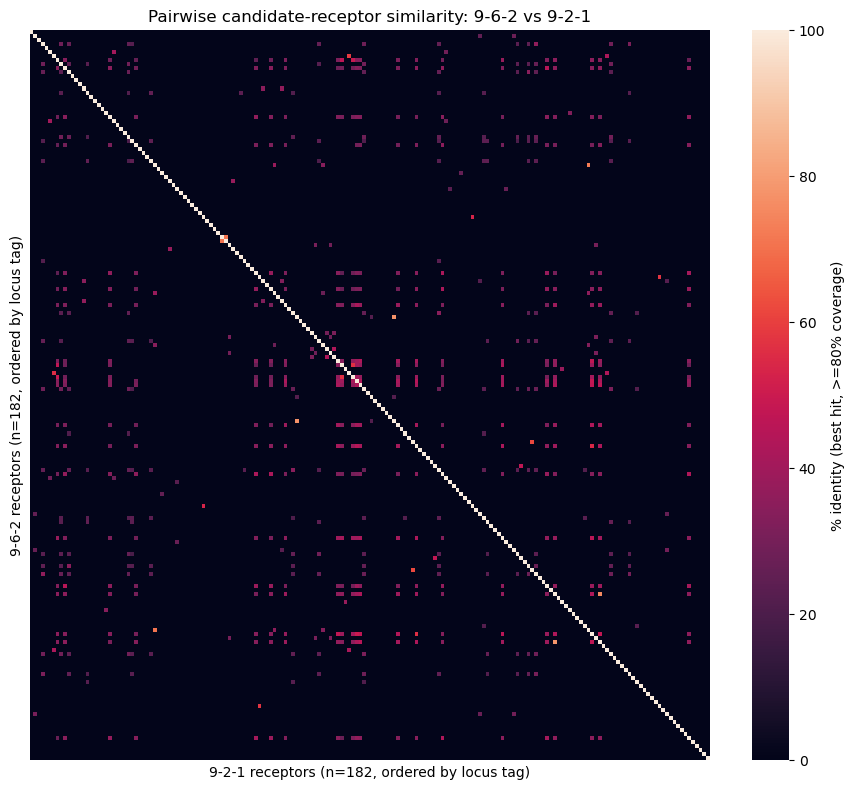

saved output/0617_receptor_similarity/heatmap_9-6-2_vs_9-2-1.png


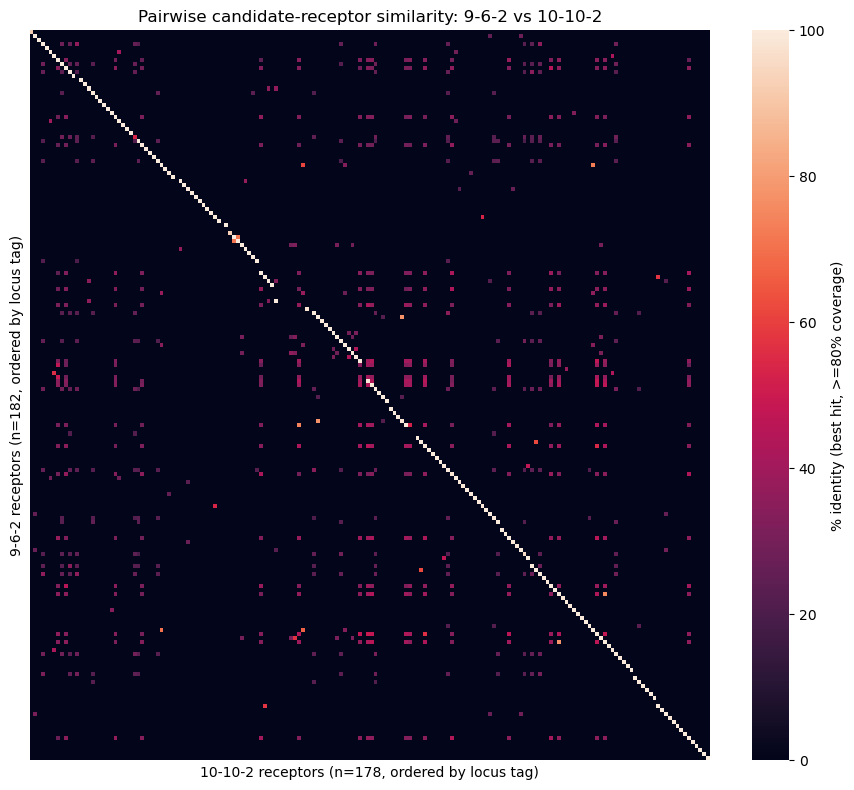

saved output/0617_receptor_similarity/heatmap_9-6-2_vs_10-10-2.png


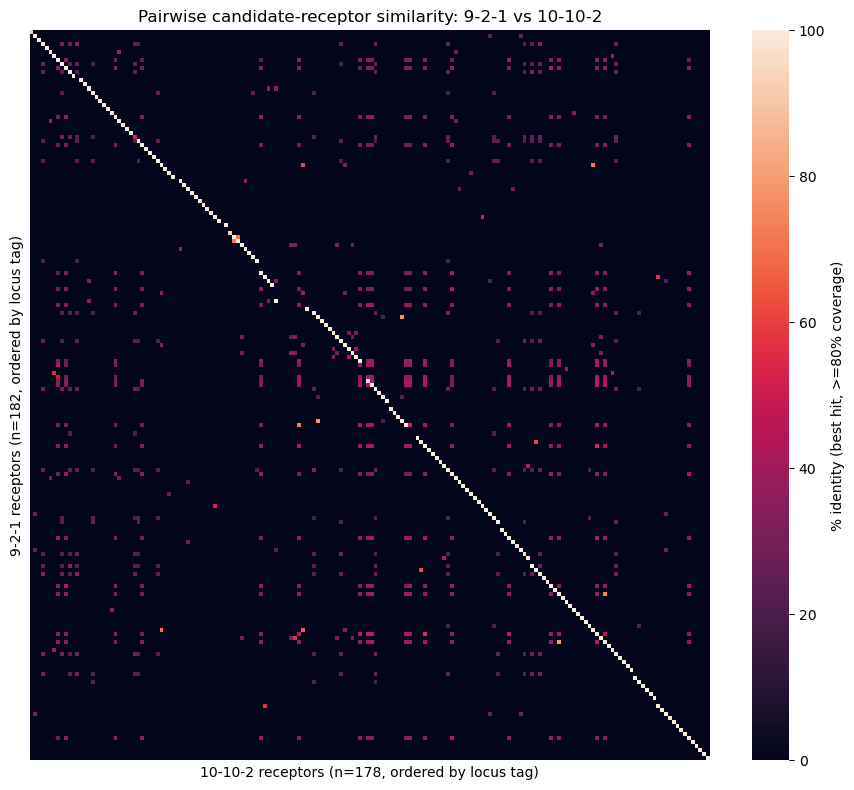

saved output/0617_receptor_similarity/heatmap_9-2-1_vs_10-10-2.png


In [5]:
for a,b in PAIRS:
    M = matrices[(a,b)]
    fig, ax = plt.subplots(figsize=(9,8))
    sns.heatmap(M, vmin=0, vmax=100, cmap="rocket",
                xticklabels=False, yticklabels=False,
                cbar_kws={"label": "% identity (best hit, >=80% coverage)"}, ax=ax)
    ax.set_xlabel(f"{b} receptors (n={M.shape[1]}, ordered by locus tag)")
    ax.set_ylabel(f"{a} receptors (n={M.shape[0]}, ordered by locus tag)")
    ax.set_title(f"Pairwise candidate-receptor similarity: {a} vs {b}")
    fig.tight_layout()
    out_png = OUT_DIR / f"heatmap_{a}_vs_{b}.png"
    fig.savefig(out_png, dpi=200)
    plt.show()
    print("saved", out_png)

## 5 - Sanity check (near-clonal pair)

In [6]:
# Sanity check: 9-6-2 (PICBEH) and 9-2-1 (OHPLIO) have identical annotations and
# matching locus tags -> near-clonal. Almost every receptor should have a ~100%
# match in the other strain. If not, the identity/coverage calc or axis ordering is broken.
M = matrices[("9-6-2","9-2-1")]
row_best = M.max(axis=1)
n_high = int((row_best>=99).sum())
print(f"9-6-2 vs 9-2-1: {n_high}/{M.shape[0]} receptors have a >=99% match in the other strain")
print(f"median best-hit identity per 9-6-2 receptor: {row_best.median():.1f}%")
assert n_high >= 150, "near-clonal expectation FAILED -- check identity/coverage or axis alignment"
print("SANITY CHECK PASSED (9-6-2 and 9-2-1 are near-clonal, as expected)")

# Note: 10-10-2 (BPBBIK) locus numbering does NOT line up with the other two, so its
# conserved hits will NOT sit on the main diagonal under locus-tag ordering -- expected,
# not a bug. (Best-hit reordering would make the conservation structure pop; optional.)

9-6-2 vs 9-2-1: 182/182 receptors have a >=99% match in the other strain
median best-hit identity per 9-6-2 receptor: 100.0%
SANITY CHECK PASSED (9-6-2 and 9-2-1 are near-clonal, as expected)
